<div style="background:linear-gradient(135deg,#4F46E5 0%,#7C3AED 55%,#9333EA 100%);padding:30px 34px;border-radius:16px;color:white;margin-bottom:14px"><div style="font-size:12px;letter-spacing:3px;text-transform:uppercase;opacity:.85">INF672 · Machine Learning · Segundo Parcial · Gestión II / 2026</div><h1 style="margin:10px 0 6px;font-size:32px;line-height:1.1">Análisis de sentimiento de reseñas de cine con Regresión Logística</h1><p style="margin:0;font-size:15px;opacity:.92">Estudiante: <b>Abdair Coca</b> · Dataset IMDB (50 000 reseñas) · 6 tareas</p></div>

**Instrucciones:** desarrollá cada tarea en este notebook, ejecutá las celdas y escribí tus respuestas en las celdas de texto marcadas ✍️. El notebook debe ejecutarse de principio a fin, sin errores y con todas las salidas visibles.

In [1]:
import glob
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

## 🟣 Ejercicio 01 — Carga y exploración

Lee el archivo y describe el conjunto de datos: **IMDB Dataset of 50K Movie Reviews** (Kaggle, autor lakshmi25npathi). Es un archivo único `IMDB Dataset.csv` con 50 000 reseñas en inglés, balanceadas entre ambas clases.

| Columna | Descripción |
|---|---|
| `review` | Texto completo de la reseña (puede contener etiquetas HTML como `<br />`). |
| `sentiment` | Etiqueta de la reseña: `positive` o `negative`. |

**1.** Carga el archivo `IMDB Dataset.csv` (está en esta misma carpeta) con pandas y describe el conjunto de datos.

**2.** Muestra la distribución de clases, verifica valores nulos y reseñas duplicadas, y decide qué hacer con ellas.

**3.** Calcula la longitud de cada reseña (en palabras) y compara su distribución entre ambas clases con un gráfico.

**Para entregar:** descripción del dataset, distribución de clases, conteo de nulos y duplicados, y gráfico de longitudes.

In [2]:
# Ej1.1 — Carga del CSV (IMDB Dataset.csv está en la misma carpeta del notebook)
df = pd.read_csv("IMDB Dataset.csv")
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
# Ej1.2 — Descripción, clases, nulos y duplicados
df.info()
print("\nDistribución de clases:")
print(df["sentiment"].value_counts())
print("\nValores nulos por columna:")
print(df.isna().sum())
print("\nReseñas duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB

Distribución de clases:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Valores nulos por columna:
review       0
sentiment    0
dtype: int64

Reseñas duplicadas: 418


In [4]:
# Ej1.3 — Decisión sobre duplicados: quitar las copias exactas
df = df.drop_duplicates().reset_index(drop=True)
print("Reseñas después de quitar duplicados:", len(df))
print(df["sentiment"].value_counts())

Reseñas después de quitar duplicados: 49582
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


             count        mean         std   min    25%    50%    75%     max
sentiment                                                                    
negative   24698.0  229.596607  165.103430   4.0  128.0  174.0  278.0  1522.0
positive   24884.0  233.090620  177.688169  10.0  125.0  172.0  284.0  2470.0


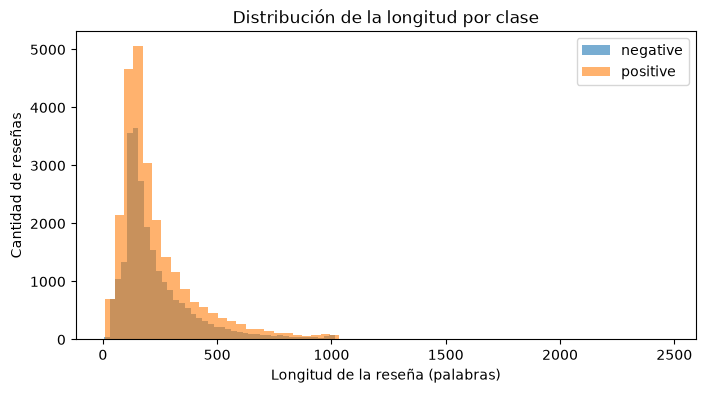

In [5]:
# Ej1.4 — Longitud en palabras por clase
df["longitud"] = df["review"].str.split().str.len()
print(df.groupby("sentiment")["longitud"].describe())

fig, ax = plt.subplots(figsize=(8, 4))
for sentimiento, grupo in df.groupby("sentiment"):
    ax.hist(grupo["longitud"], bins=60, alpha=0.6, label=sentimiento)
ax.set_xlabel("Longitud de la reseña (palabras)")
ax.set_ylabel("Cantidad de reseñas")
ax.set_title("Distribución de la longitud por clase")
ax.legend()
plt.show()

✍️ **Ej1 — interpretación:** ¿qué hiciste con los duplicados y por qué? ¿Qué clase tiene reseñas más largas?

*Eliminé las 418 reseñas duplicadas (copias exactas). Si quedan repetidas en entrenamiento y en prueba, el modelo puede memorizarlas y la exactitud sale inflada. Quedan 49 582 reseñas, casi igual de balanceadas (24 884 positive y 24 698 negative). Las longitudes son casi iguales entre clases: la mediana es de 174 palabras en negative y 172 en positive, y la media de 230 y 233. Ninguna clase tiene reseñas claramente más largas; solo positive llega a los extremos más altos (hasta 2 470 palabras).*

## 🟣 Ejercicio 02 — Preprocesamiento del texto

Adapta la función de preprocesamiento de clase a este dataset.

**1.** Inspecciona varias reseñas e identifica qué elementos "sucios" aparecen; elimina solo los que realmente existan.

**2.** Las stopwords de NLTK incluyen palabras como `not`, `no` o `but`. Analiza si eliminarlas afecta a un problema de sentimiento y decide si las conservas. **Justifica tu decisión.**

**3.** Trabaja inicialmente con una muestra de 5 000 reseñas.

**Para entregar:** ejemplos de reseñas sucias, la decisión sobre stopwords con su justificación y la función de preprocesamiento.

In [6]:
# Ej2.1 — Inspección: qué elementos "sucios" existen realmente
for texto in df["review"].sample(3, random_state=42):
    print(texto[:300])
    print("---")

patrones = {
    "etiquetas HTML": r"<[^>]+>",
    "URLs": r"http\S+|www\.\S+",
    "dígitos": r"\d",
    "signos de puntuación": r"[^\w\s]",
}
for nombre, patron in patrones.items():
    print(f"{nombre}: {df['review'].str.contains(patron, regex=True).sum()} reseñas")

"Soul Plane" is a horrible attempt at comedy that only should appeal people with thick skulls, bloodshot eyes and furry pawns. <br /><br />The plot is not only incoherent but also non-existent, acting is mostly sub sub-par with a gang of highly moronic and dreadful characters thrown in for bad measu
---
Guest from the Future tells a fascinating story of time travel, friendship, battle of good and evil -- all with a small budget, child actors, and few special effects. Something for Spielberg and Lucas to learn from. ;) A sixth-grader Kolya "Nick" Gerasimov finds a time machine in the basement of a d
---
"National Treasure" (2004) is a thoroughly misguided hodge-podge of plot entanglements that borrow from nearly every cloak and dagger government conspiracy cliché that has ever been written. The film stars Nicholas Cage as Benjamin Franklin Gates (how precious is that, I ask you?); a seemingly norma
---
etiquetas HTML: 28968 reseñas


URLs: 196 reseñas
dígitos: 27786 reseñas
signos de puntuación: 49578 reseñas


In [7]:
# Ej2.2 — Stopwords de NLTK, conservando las negaciones
nltk.download("stopwords", quiet=True)
stop_nltk = set(stopwords.words("english"))
negaciones = {
    "no", "not", "nor", "but",
    "don", "doesn", "didn", "isn", "wasn", "aren", "weren", "won",
    "wouldn", "couldn", "shouldn", "hasn", "haven", "hadn",
}
stop_a_quitar = stop_nltk - negaciones
stemmer = PorterStemmer()
print("Stopwords de NLTK:", len(stop_nltk), "| a quitar:", len(stop_a_quitar))

Stopwords de NLTK: 198 | a quitar: 180


In [8]:
# Ej2.3 — ¿Cuántas veces aparecen las negaciones en cada clase?
for palabra in ["not", "no", "but", "nor"]:
    cuenta = df["review"].str.lower().str.count(rf"\b{palabra}\b")
    print(palabra, "->", cuenta.groupby(df["sentiment"]).sum().to_dict())

not -> {'negative': 32067, 'positive': 28204}


no -> {'negative': 15888, 'positive': 9196}


but -> {'negative': 42350, 'positive': 40573}


nor -> {'negative': 776, 'positive': 496}


In [9]:
# Ej2.4 — Función de preprocesamiento
def preprocesar(texto):
    texto = texto.lower()
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)  # URLs (aparecen en ~200 reseñas)
    texto = re.sub(r"<[^>]+>", " ", texto)   # etiquetas HTML como <br />
    texto = re.sub(r"[^a-z\s]", " ", texto)  # números y signos de puntuación
    palabras = [p for p in texto.split() if p not in stop_a_quitar]
    return " ".join(stemmer.stem(p) for p in palabras)

preprocesar(df["review"].iloc[0])

'one review mention watch oz episod hook right exactli happen first thing struck oz brutal unflinch scene violenc set right word go trust not show faint heart timid show pull no punch regard drug sex violenc hardcor classic use word call oz nicknam given oswald maximum secur state penitentari focus mainli emerald citi experiment section prison cell glass front face inward privaci not high agenda em citi home mani aryan muslim gangsta latino christian italian irish scuffl death stare dodgi deal shadi agreement never far away would say main appeal show due fact goe show wouldn dare forget pretti pictur paint mainstream audienc forget charm forget romanc oz doesn mess around first episod ever saw struck nasti surreal couldn say readi but watch develop tast oz got accustom high level graphic violenc not violenc but injustic crook guard sold nickel inmat kill order get away well manner middl class inmat turn prison bitch due lack street skill prison experi watch oz may becom comfort uncomfo

In [10]:
# Ej2.5 — Muestra de 5 000 reseñas y preprocesamiento
muestra = df.sample(n=5000, random_state=42).reset_index(drop=True)
muestra["review_limpia"] = muestra["review"].apply(preprocesar)
muestra[["review_limpia", "sentiment"]].head()

,review_limpia,sentiment
0,soul plane horribl attempt comedi appeal peopl...,negative
1,guest futur tell fascin stori time travel frie...,positive
2,nation treasur thoroughli misguid hodg podg pl...,negative
3,ok first said want check whether movi averag r...,negative
4,haven alway fan but show grew wasn season star...,positive


✍️ **Ej2 — interpretación:** ¿qué elementos "sucios" encontraste y cuáles eliminaste? ¿Eliminar `not`, `no` y `but` afecta a un problema de sentimiento? ¿Qué decidiste y por qué?

*Encontré los cuatro tipos de elementos sucios: etiquetas HTML como `<br />` (28 968 reseñas), URLs (196), dígitos (27 786) y signos de puntuación (49 578). Como existen en el dataset, los elimino todos. De las 198 stopwords de NLTK quito 180 y conservo 18 palabras de negación. Conservo las negaciones porque se concentran en las reseñas negativas: `no` aparece 15 888 veces en negative y 9 196 en positive, y `not` 32 067 veces frente a 28 204. Si las quito, "not good" se convierte en "good", que suena positivo y confunde al modelo. Conservo también `but` (aparece casi igual en ambas clases, 42 350 y 40 573) porque marca contrastes como "good but...", y `nor`. Esta decisión la justifico con los conteos y el razonamiento; no medí la exactitud con y sin negaciones.*

## 🟣 Ejercicio 03 — División de los datos

**1.** Separa los datos en entrenamiento (80 %) y prueba (20 %) con `train_test_split`, usando `stratify` y `random_state=42`. Convierte la etiqueta a `1` (positive) y `0` (negative).

**2.** Explica por qué el vectorizador debe ajustarse (`fit`) solo con los datos de entrenamiento.

**Para entregar:** tamaños de cada partición, proporciones de clase y la explicación del `fit`.

In [11]:
# Ej3.1 — Etiqueta binaria y split 80/20 estratificado
muestra["etiqueta"] = muestra["sentiment"].map({"positive": 1, "negative": 0})
X = muestra["review_limpia"]
y = muestra["etiqueta"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Entrenamiento:", len(X_train), "| Prueba:", len(X_test))
print("Proporción positive en train:", round(y_train.mean(), 3))
print("Proporción positive en test: ", round(y_test.mean(), 3))

Entrenamiento: 4000 | Prueba: 1000
Proporción positive en train: 0.498
Proporción positive en test:  0.498


✍️ **Ej3 — interpretación:** ¿por qué el vectorizador se ajusta solo con los datos de entrenamiento?

*Si el vocabulario y los pesos IDF se calculan con todas las reseñas, el modelo recibe información de las reseñas de prueba durante el entrenamiento (fuga de datos). La evaluación queda optimista y no refleja cómo se comportaría con reseñas nuevas. Por eso `fit` se llama solo con `X_train`, y en prueba solo se usa `transform`.*

## 🟣 Ejercicio 04 — Vectorización

Construye dos representaciones del texto y compáralas:

- **Modelo A:** Bag of Words con `CountVectorizer`.
- **Modelo B:** `TfidfVectorizer`. Investiga qué hace TF-IDF y explícalo con tus palabras en una celda Markdown (está más abajo).
- Experimenta con al menos un parámetro (`max_features`, `min_df` o `ngram_range`) y registra su efecto.

In [12]:
# Ej4.1 — Modelo A (Bag of Words) y Modelo B (TF-IDF), ajustados solo con train
vec_bow = CountVectorizer()
X_bow_train = vec_bow.fit_transform(X_train)
X_bow_test = vec_bow.transform(X_test)

vec_tfidf = TfidfVectorizer()
X_tfidf_train = vec_tfidf.fit_transform(X_train)
X_tfidf_test = vec_tfidf.transform(X_test)

print("Vocabulario BoW:", X_bow_train.shape[1])
print("Vocabulario TF-IDF:", X_tfidf_train.shape[1])

Vocabulario BoW: 23672
Vocabulario TF-IDF: 23672


**¿Qué hace TF-IDF?** Pondera cada palabra de cada reseña con dos factores. *TF* (term frequency) cuenta cuántas veces aparece la palabra en esa reseña. *IDF* (inverse document frequency) mide qué tan rara es la palabra en todo el conjunto. Así, las palabras que aparecen en casi todas las reseñas (como *movie* o *film*) reciben un peso bajo, mientras que las palabras que se repiten en una reseña pero son poco comunes en el resto reciben un peso alto. Bag of Words solo cuenta apariciones y no distingue entre palabras informativas y palabras comunes.

In [13]:
# Ej4.2 — Experimento: ngram_range y max_features (TF-IDF)
filas = []
for ngram in [(1, 1), (1, 2)]:
    for max_f in [1000, 5000, None]:
        vec = TfidfVectorizer(ngram_range=ngram, max_features=max_f)
        Xt_train = vec.fit_transform(X_train)
        Xt_test = vec.transform(X_test)
        modelo = LogisticRegression(max_iter=1000).fit(Xt_train, y_train)
        acc = accuracy_score(y_test, modelo.predict(Xt_test))
        filas.append([
            str(ngram),
            "sin límite" if max_f is None else max_f,
            Xt_train.shape[1],
            round(acc, 4),
        ])

pd.DataFrame(filas, columns=["ngram_range", "max_features", "n_features", "Exactitud test"])

,ngram_range,max_features,n_features,Exactitud test
0,"(1, 1)",1000,1000,0.833
1,"(1, 1)",5000,5000,0.841
2,"(1, 1)",sin límite,23672,0.846
3,"(1, 2)",1000,1000,0.837
4,"(1, 2)",5000,5000,0.852
5,"(1, 2)",sin límite,362834,0.838


✍️ **Ej4 — interpretación:** ¿qué efecto tuvo el parámetro que probaste sobre el número de columnas y sobre la exactitud?

*Con `ngram_range=(1, 1)` la exactitud sube al aumentar `max_features`: 0.833 con 1 000 columnas, 0.841 con 5 000 y 0.846 sin límite (23 672 columnas). Con bigramas `(1, 2)` el mejor resultado es 0.852 con `max_features=5000`. Sin límite, los bigramas generan 362 834 columnas y la exactitud baja a 0.838: muchas combinaciones aparecen muy pocas veces y no aportan información útil. Ojo: las diferencias son de alrededor de 1 punto con 1 000 reseñas de prueba (cada punto son unas 10 reseñas), así que con una sola ejecución no son concluyentes.*

## 🟣 Ejercicio 05 — Entrenamiento y evaluación

Entrena un `LogisticRegression` con cada representación y evalúalos sobre el conjunto de prueba.

- Reporta exactitud, precisión, recall y F1, y muestra la matriz de confusión de cada modelo.
- Resume los resultados en una tabla comparativa e indica qué modelo eliges y por qué.

In [14]:
# Ej5.1 — LogisticRegression con cada representación
representaciones = {
    "BoW (CountVectorizer)": (vec_bow, X_bow_train, X_bow_test),
    "TF-IDF (TfidfVectorizer)": (vec_tfidf, X_tfidf_train, X_tfidf_test),
}

modelos = {}
matrices = {}
filas = []
for nombre, (vec, Xtr, Xte) in representaciones.items():
    modelo = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
    pred = modelo.predict(Xte)
    modelos[nombre] = (vec, modelo)
    matrices[nombre] = confusion_matrix(y_test, pred)
    filas.append([
        nombre,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
    ])

tabla = pd.DataFrame(filas, columns=["Modelo", "Exactitud", "Precisión", "Recall", "F1"])
tabla.round(4)

,Modelo,Exactitud,Precisión,Recall,F1
0,BoW (CountVectorizer),0.840,0.8238,0.8635,0.8431
1,TF-IDF (TfidfVectorizer),0.846,0.8209,0.8835,0.8511


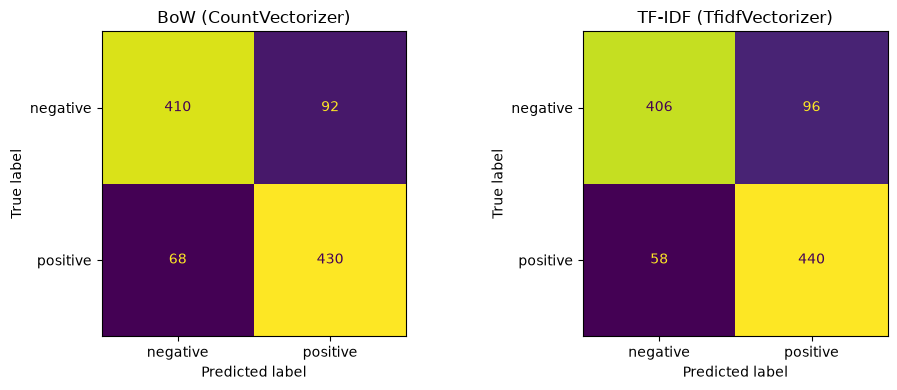

In [15]:
# Ej5.2 — Matrices de confusión (0 = negative, 1 = positive)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, cm) in zip(ejes, matrices.items()):
    ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

✍️ **Ej5 — interpretación:** ¿qué modelo eliges y por qué? Según las matrices de confusión, ¿qué tipo de error comete más cada modelo?

*Elijo TF-IDF: tiene la mayor exactitud (0.846 frente a 0.840), el mayor F1 (0.851 frente a 0.843) y el mayor recall (0.884 frente a 0.864). La diferencia es pequeña, así que no es una victoria clara. En las matrices (filas = real, columnas = predicha), BoW tiene 92 falsos positivos y 68 falsos negativos; TF-IDF tiene 96 falsos positivos y 58 falsos negativos. Los dos modelos se equivocan más al predecir positive para una reseña negative. TF-IDF encuentra más reseñas positivas (menos falsos negativos) a cambio de algunos falsos positivos más.*

## 🟣 Ejercicio 06 — Interpretación del modelo

Analiza lo que aprendió tu mejor modelo (el de mayor F1 en el Ejercicio 05).

- Muestra las 15 palabras con coeficientes más positivos y las 15 más negativos. ¿Tienen sentido?
- Escribe 3 reseñas propias (una claramente positiva, una negativa y una ambigua o sarcástica) y obtén su clase y probabilidad con `predict_proba`.
- Elige 2 reseñas del conjunto de prueba mal clasificadas y explica por qué crees que el modelo falló.

In [16]:
# Ej6.1 — 15 palabras con coeficientes más positivos y más negativos del mejor modelo
mejor_nombre = tabla.sort_values("F1", ascending=False).iloc[0]["Modelo"]
vectorizer, modelo_mejor = modelos[mejor_nombre]

coeficientes = pd.Series(
    modelo_mejor.coef_[0], index=vectorizer.get_feature_names_out()
).sort_values()
print("Mejor modelo (mayor F1):", mejor_nombre)
print("\n15 más NEGATIVAS:")
print(coeficientes.head(15))
print("\n15 más POSITIVAS:")
print(coeficientes.tail(15).sort_values(ascending=False))

Mejor modelo (mayor F1): TF-IDF (TfidfVectorizer)

15 más NEGATIVAS:
bad          -4.802527
worst        -4.189156
wast         -3.351306
bore         -3.177995
aw           -3.067821
noth         -2.756341
horribl      -2.450400
disappoint   -2.445461
stupid       -2.444560
terribl      -2.383305
script       -2.087241
fail         -2.068418
minut        -2.048363
no           -2.031731
even         -2.010383
dtype: float64

15 más POSITIVAS:
great        4.137870
love         2.936329
excel        2.696369
best         2.452322
well         2.265566
perfect      2.249646
enjoy        2.133720
beauti       2.031808
definit      2.004199
see          1.917656
still        1.758855
also         1.726687
recommend    1.720323
perform      1.705893
life         1.697789
dtype: float64


In [17]:
# Ej6.2 — Tres reseñas propias: clase y probabilidad con predict_proba
mis_resenas = {
    "claramente positiva": "I absolutely loved this movie. The acting was brilliant, the story moved me, and I would happily watch it again.",
    "claramente negativa": "This film was a total waste of time. The plot made no sense, the dialogue was painful, and I regret buying a ticket.",
    "ambigua / sarcástica": "Oh great, another two hours of explosions and no plot. Truly a masterpiece of how not to make a movie, although the popcorn was good.",
}
textos = [preprocesar(t) for t in mis_resenas.values()]
probas = modelo_mejor.predict_proba(vectorizer.transform(textos))

for (tipo, original), p in zip(mis_resenas.items(), probas):
    clase = "positive" if p[1] >= 0.5 else "negative"
    print(f"{tipo}: {clase} | P(positive) = {p[1]:.3f}")
    print("   ", original)

claramente positiva: positive | P(positive) = 0.748
    I absolutely loved this movie. The acting was brilliant, the story moved me, and I would happily watch it again.
claramente negativa: negative | P(positive) = 0.098
    This film was a total waste of time. The plot made no sense, the dialogue was painful, and I regret buying a ticket.
ambigua / sarcástica: positive | P(positive) = 0.507
    Oh great, another two hours of explosions and no plot. Truly a masterpiece of how not to make a movie, although the popcorn was good.


In [18]:
# Ej6.3 — Reseñas de prueba mal clasificadas por el mejor modelo
pred_test = modelo_mejor.predict(vectorizer.transform(X_test))
mal = pred_test != y_test.values
errores = muestra.loc[X_test.index[mal], ["review", "sentiment"]].copy()
errores["predicha"] = np.where(pred_test[mal] == 1, "positive", "negative")

print("Mal clasificadas en prueba:", len(errores), "de", len(y_test))
for _, fila in errores.head(2).iterrows():
    print(f"Real: {fila['sentiment']} | Predicha: {fila['predicha']}")
    print(fila["review"][:600])
    print("---")

Mal clasificadas en prueba: 154 de 1000
Real: negative | Predicha: positive
Man, I really wanted to like these shows. I am starving for some good television and I applaud TNT for providing these "opportunites". But, sadly, I am in the minority I guess when it comes to the Cinematic Stephen King. As brilliant as King's writing is, the irony is that it simply doesn't translate well to the screen, big or small. With few exceptions (very few), the King experience cannot be filmed with the same impact that the stories have when read. Many people would disagree with this, but I'm sure that in their heart of hearts they have to admit that the best filmed King story is but a 
---
Real: negative | Predicha: positive
A chilling and gory tale of a couple inheriting a 150 room Italian castle while still grieving the loss of their young son. The couples marriage seems to be on the rocks due to the car accident that took the life of their son and left their daughter blind. Upon taking inventory of t

✍️ **Ej6 — interpretación:** ¿tienen sentido las palabras con coeficiente más positivo y más negativo? ¿Tus 3 reseñas salieron como esperabas? ¿Por qué crees que falló cada una de las 2 reseñas elegidas?

*La mayoría de las palabras tienen sentido. Las más negativas son insultos o expresiones de decepción (bad, worst, horrible, terrible, stupid, disappoint, bore). Las más positivas también: great, love, excellent, best, perfect, enjoy, recommend. Los nombres cortados son raíces de Porter: "wast" viene de waste, "aw" de awful, "noth" de nothing. Algunas palabras no tienen un sentido directo, como script, minut, even, see, still, also y well. Mi hipótesis es que aparecen en contextos de una clase, por ejemplo "minutes wasted" o "even worse", pero el modelo solo cuenta palabras y no lo puedo confirmar sin más análisis.*

*Mis 3 reseñas: la positiva (P(positive) = 0.748) y la negativa (0.098) salieron como esperaba. La ambigua o sarcástica dio 0.507, apenas positive. El modelo se fija en "great", "masterpiece" y "good" y no entiende el sarcasmo; una probabilidad cerca de 0.5 muestra que duda.*

*Reseñas mal clasificadas (ambas reales negative, predichas positive): (1) reseña de 296 palabras sobre las adaptaciones de Stephen King. Tiene muchas palabras positivas ("brilliant", "best", "applaud", "good") y una conclusión negativa ("doesn't translate well", "better luck next time"). Como el modelo no mira el orden ni el contexto, suma lo positivo y se equivoca. (2) reseña de 96 palabras sobre una película de terror. Describe la trama de forma neutral y usa adjetivos positivos ("great horror atmosphere", "pretty gory"). El modelo se deja llevar por esos adjetivos.*

## 🏁 Conclusiones

✍️ Resume qué aprendiste: qué representación funcionó mejor, qué limitaciones tiene el modelo y qué harías para mejorarlo (por ejemplo, usar más reseñas o un modelo distinto).

*Aprendí que el preprocesamiento importa: quitar HTML, URLs y signos, y conservar las negaciones. TF-IDF dio un resultado ligeramente mejor que BoW (F1 0.851 frente a 0.843), pero la diferencia es pequeña y sale de una sola partición de prueba de 1 000 reseñas. Limitaciones: el modelo ignora el orden de las palabras, así que no entiende la ironía ni las reseñas mixtas, y los modelos se entrenaron con solo 4 000 reseñas. Qué haría después: escalar a las 49 582 reseñas (no lo probé), usar bigramas con `max_features=5000` (mejor exactitud del Ejercicio 4, 0.852) y validar con validación cruzada para saber si la diferencia entre modelos es real.*